# Deep learning models: dense networks and sequence models

This notebook covers two deep learning examples:

- **Part 1** — a simple dense (fully connected) network with a softmax output, trained on the Iris dataset for multi-class classification.
- **Part 2** — nine recurrent architectures (`SimpleRNN`, `LSTM`, `GRU`, each plain, bidirectional, and stacked), trained on sine wave data for next-step prediction.

## Part 1: Dense neural network on Iris data

The Iris dataset has 150 flower samples, each with 4 numeric features (sepal length, sepal width, petal length, petal width), and the goal is to predict which of 3 species a flower belongs to. It's a classic, simple dataset for tabular classification, a good fit for a small feedforward network with a softmax output layer.

## numpy = 2.2.6
## pandas = 2.3.3
## tensorflow = 2.21.0
## torch = 2.12.0

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

np.random.seed(42)

### 1.1 Loading and preparing the data

We split the data into train/test sets, scale the features (helps training converge faster), and one-hot encode the labels since we'll use `categorical_crossentropy` as the loss.

In [22]:
iris = load_iris()
X, y = iris.data, iris.target  # X: (150, 4), y: (150,) with values 0, 1, 2

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

y_train_oh = to_categorical(y_train, num_classes=3)
y_test_oh = to_categorical(y_test, num_classes=3)

print(f"Train shape: {X_train.shape}, Test shape: {X_test.shape}")

Train shape: (120, 4), Test shape: (30, 4)


### 1.2 Building the model

4 input features map to 4 input nodes, a small hidden layer with ReLU activation, and an output layer of 3 units with softmax giving a probability for each species.

In [23]:
iris_model = Sequential()
iris_model.add(Dense(8, activation='relu', input_shape=(4,)))
iris_model.add(Dense(3, activation='softmax'))

iris_model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

iris_model.summary()

c:\Users\blk4524\AppData\Local\anaconda3\envs\nn\lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_11 (Dense)                │ (None, 8)              │            40 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 67 (268.00 B)

 Trainable params: 67 (268.00 B)

 Non-trainable params: 0 (0.00 B)

### 1.3 Training and evaluating

Test accuracy: 0.9000


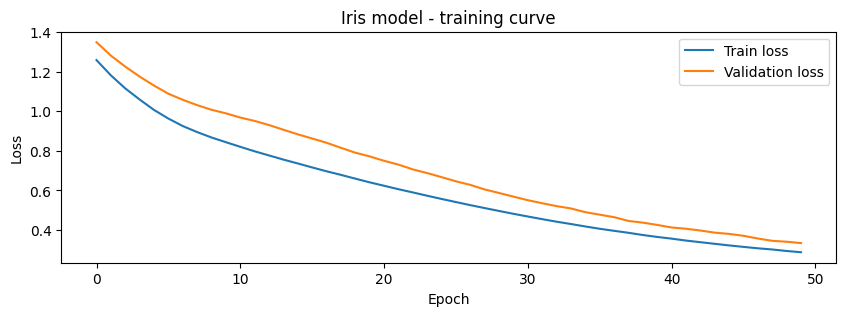

In [24]:
history = iris_model.fit(
    X_train, y_train_oh,
    epochs=50,
    batch_size=8,
    validation_split=0.1,
    verbose=0
)

loss, accuracy = iris_model.evaluate(X_test, y_test_oh, verbose=0)
print(f"Test accuracy: {accuracy:.4f}")

plt.figure(figsize=(10, 3))
plt.plot(history.history['loss'], label='Train loss')
plt.plot(history.history['val_loss'], label='Validation loss')
plt.title("Iris model - training curve")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

### 1.4 Predictions and classification report

`model.predict` returns softmax probabilities for each of the 3 classes per sample. `np.argmax` picks the highest probability class as the final prediction, then `classification_report` gives precision, recall, and F1-score per class, more informative than a single accuracy number.

In [25]:
y_pred_probs = iris_model.predict(X_test, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

print(classification_report(y_test, y_pred, target_names=iris.target_names))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.70      0.82        10
   virginica       0.77      1.00      0.87        10

    accuracy                           0.90        30
   macro avg       0.92      0.90      0.90        30
weighted avg       0.92      0.90      0.90        30



## Part 2: Sequence models on sine wave data — RNN, LSTM, and GRU

This part walks through nine recurrent architectures, all trained to predict the next point in a noisy sine wave:

- Plain: `SimpleRNN`, `LSTM`, `GRU`
- Bidirectional: `Bidirectional(SimpleRNN)`, `Bidirectional(LSTM)`, `Bidirectional(GRU)`
- Stacked: 2-layer `SimpleRNN`, 2-layer `LSTM`, 2-layer `GRU`

Each model uses the same data split and the same training setup, so the test MSE at the end is a fair comparison across architectures.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, LSTM, GRU, Bidirectional, Dense

np.random.seed(42)

## 1. Generating sine wave data

We create a sine wave with a small amount of added noise, since a perfectly smooth curve makes the task trivial for any model.

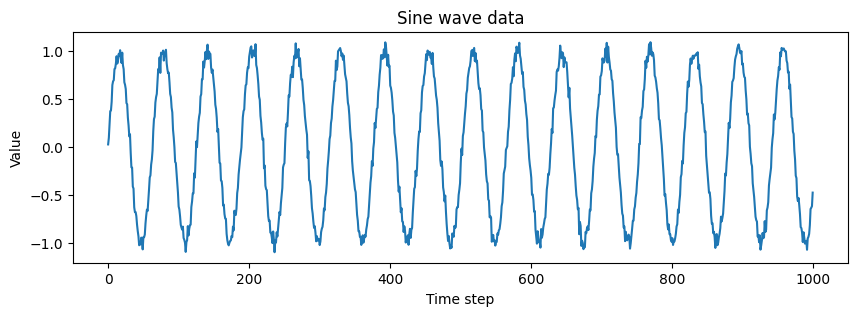

In [2]:
def generate_sine_wave(n_points=1000, noise_std=0.05):
    x = np.linspace(0, 100, n_points)
    y = np.sin(x) + np.random.normal(0, noise_std, n_points)
    return y

data = generate_sine_wave()

plt.figure(figsize=(10, 3))
plt.plot(data)
plt.title("Sine wave data")
plt.xlabel("Time step")
plt.ylabel("Value")
plt.show()

## 2. Creating input sequences

Recurrent models predict the next value from a window of past values. We slide a fixed-size window across the data: each input is `WINDOW_SIZE` consecutive points, and the target is the point right after that window. We don't shuffle the train/test split since this is a time series, the test set should come after the training set in time.

In [3]:
def create_sequences(data, window_size):
    X, y = [], []
    for i in range(len(data) - window_size):
        X.append(data[i:i + window_size])
        y.append(data[i + window_size])
    return np.array(X), np.array(y)

WINDOW_SIZE = 50
X, y = create_sequences(data, WINDOW_SIZE)

# Reshape for RNN input: (samples, timesteps, features)
X = X.reshape((X.shape[0], X.shape[1], 1))

split = int(0.8 * len(X))
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

print(f"Train shape: {X_train.shape}, Test shape: {X_test.shape}")

Train shape: (760, 50, 1), Test shape: (190, 50, 1)


## 3. Training and evaluation helper

To avoid repeating the same training, evaluation, and plotting code nine times, we define one helper function that takes any compiled model and runs the full cycle. Results get stored in a dictionary so we can compare all architectures at the end.

In [4]:
results = {}

def train_and_evaluate(model, name, epochs=20):
    model.compile(optimizer='adam', loss='mse')
    model.fit(
        X_train, y_train,
        epochs=epochs,
        batch_size=32,
        validation_split=0.1,
        verbose=0
    )

    y_pred = model.predict(X_test, verbose=0)
    mse = mean_squared_error(y_test, y_pred)
    results[name] = mse
    print(f"{name} - Test MSE: {mse:.5f}")

    plt.figure(figsize=(10, 3))
    plt.plot(y_test, label='Actual')
    plt.plot(y_pred, label='Predicted')
    plt.title(f"{name} - predictions vs actual")
    plt.legend()
    plt.show()

    return mse

## 4. Simple RNN

A `SimpleRNN` layer passes its hidden state forward one timestep at a time. It's the most basic recurrent layer, but it tends to struggle with longer sequences because gradients can vanish as they're propagated back through many timesteps.

c:\Users\blk4524\AppData\Local\anaconda3\envs\nn\lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 32)             │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,121 (4.38 KB)

 Trainable params: 1,121 (4.38 KB)

 Non-trainable params: 0 (0.00 B)

Simple RNN - Test MSE: 0.00273


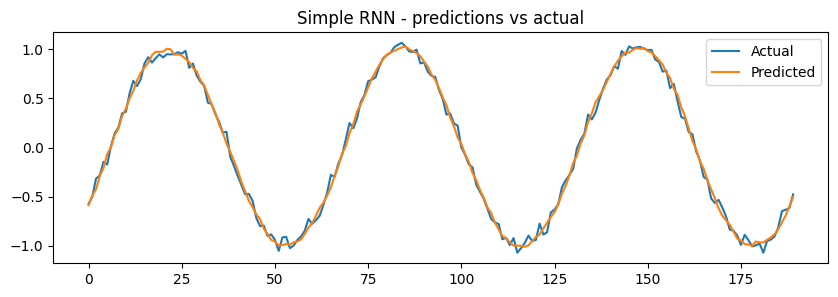

0.002734313564320779

In [5]:
rnn_model = Sequential([
    SimpleRNN(32, input_shape=(WINDOW_SIZE, 1)),
    Dense(1)
])
rnn_model.summary()
train_and_evaluate(rnn_model, "Simple RNN")

## 5. LSTM

LSTM (Long Short-Term Memory) adds a separate cell state plus input, forget, and output gates. These gates let the network learn what to keep, what to discard, and what to output at each timestep, which helps it retain information over much longer sequences than a plain RNN.

In [3]:
lstm_model = Sequential([
    LSTM(32, input_shape=(WINDOW_SIZE, 1)),
    Dense(1)
])
lstm_model.summary()
train_and_evaluate(lstm_model, "LSTM")

NameError: name 'LSTM' is not defined

In [4]:
tf.keras.models.Sequential??

Object `tf.keras.models.Sequential` not found.


## 6. GRU

GRU (Gated Recurrent Unit) simplifies LSTM's gating down to two gates (update and reset) and merges the cell state into the hidden state. It has fewer parameters than LSTM and trains faster, while often performing comparably on simpler tasks like this one.

c:\Users\blk4524\AppData\Local\anaconda3\envs\nn\lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 32)             │         3,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,393 (13.25 KB)

 Trainable params: 3,393 (13.25 KB)

 Non-trainable params: 0 (0.00 B)

GRU - Test MSE: 0.00331


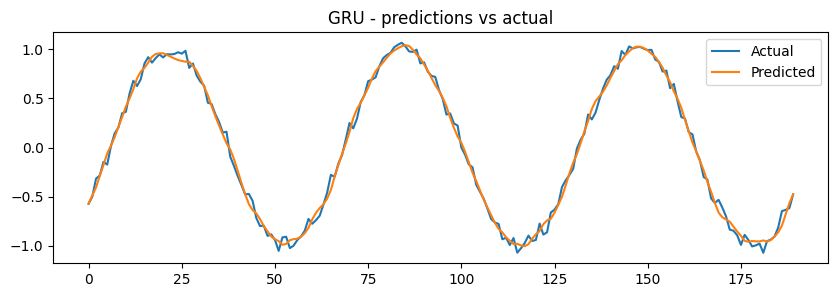

0.0033149603204277265

In [7]:
gru_model = Sequential([
    GRU(32, input_shape=(WINDOW_SIZE, 1)),
    Dense(1)
])
gru_model.summary()
train_and_evaluate(gru_model, "GRU")

## 7. Bidirectional models

A `Bidirectional` wrapper runs two copies of a recurrent layer over the sequence, one reading left-to-right and one reading right-to-left, then concatenates their outputs. This gives the model context from both directions, useful when the entire sequence is available upfront. Note this isn't suitable for live forecasting, where future values aren't known yet, but it's a fair architecture to test here since we already have the full sequence in memory.

### 7.1 Bidirectional RNN

c:\Users\blk4524\AppData\Local\anaconda3\envs\nn\lib\site-packages\keras\src\layers\rnn\bidirectional.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional (Bidirectional)   │ (None, 64)             │         2,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,241 (8.75 KB)

 Trainable params: 2,241 (8.75 KB)

 Non-trainable params: 0 (0.00 B)

Bidirectional RNN - Test MSE: 0.00462


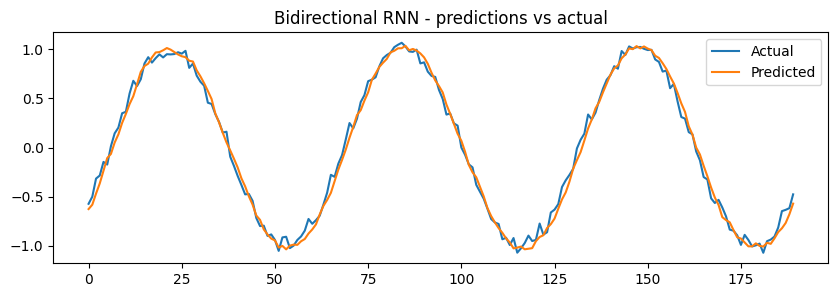

0.004621507033221745

In [8]:
bi_rnn_model = Sequential([
    Bidirectional(SimpleRNN(32), input_shape=(WINDOW_SIZE, 1)),
    Dense(1)
])
bi_rnn_model.summary()
train_and_evaluate(bi_rnn_model, "Bidirectional RNN")

### 7.2 Bidirectional LSTM

c:\Users\blk4524\AppData\Local\anaconda3\envs\nn\lib\site-packages\keras\src\layers\rnn\bidirectional.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional_1 (Bidirectional) │ (None, 64)             │         8,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,769 (34.25 KB)

 Trainable params: 8,769 (34.25 KB)

 Non-trainable params: 0 (0.00 B)

Bidirectional LSTM - Test MSE: 0.00262


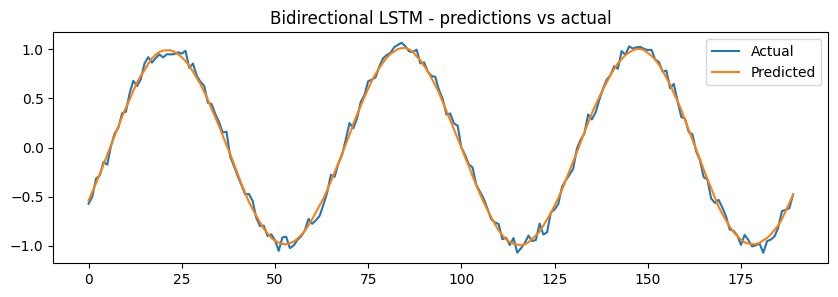

0.002620358947369105

In [9]:
bi_lstm_model = Sequential([
    Bidirectional(LSTM(32), input_shape=(WINDOW_SIZE, 1)),
    Dense(1)
])
bi_lstm_model.summary()
train_and_evaluate(bi_lstm_model, "Bidirectional LSTM")

### 7.3 Bidirectional GRU

c:\Users\blk4524\AppData\Local\anaconda3\envs\nn\lib\site-packages\keras\src\layers\rnn\bidirectional.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional_2 (Bidirectional) │ (None, 64)             │         6,720 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,785 (26.50 KB)

 Trainable params: 6,785 (26.50 KB)

 Non-trainable params: 0 (0.00 B)

Bidirectional GRU - Test MSE: 0.00293


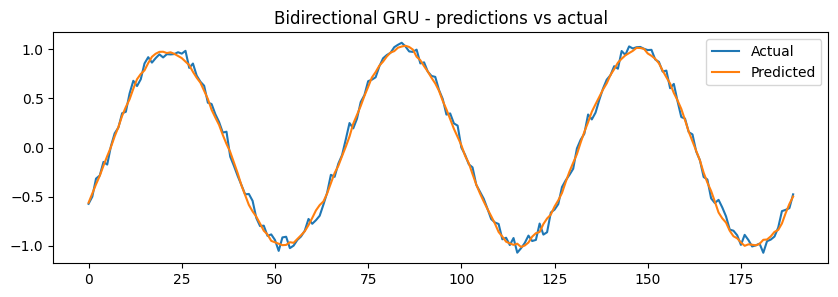

0.0029335078768490414

In [10]:
bi_gru_model = Sequential([
    Bidirectional(GRU(32), input_shape=(WINDOW_SIZE, 1)),
    Dense(1)
])
bi_gru_model.summary()
train_and_evaluate(bi_gru_model, "Bidirectional GRU")

## 8. Stacked models

Stacking multiple recurrent layers lets each layer learn increasingly abstract temporal patterns, similar to how stacking dense layers builds increasingly abstract feature representations. The key requirement is setting `return_sequences=True` on every recurrent layer except the last one, since each layer needs to pass a full sequence (not just its final state) to the layer above it.

### 8.1 Stacked RNN

c:\Users\blk4524\AppData\Local\anaconda3\envs\nn\lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_2 (SimpleRNN)        │ (None, 50, 32)         │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_3 (SimpleRNN)        │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,201 (12.50 KB)

 Trainable params: 3,201 (12.50 KB)

 Non-trainable params: 0 (0.00 B)

Stacked RNN - Test MSE: 0.00362


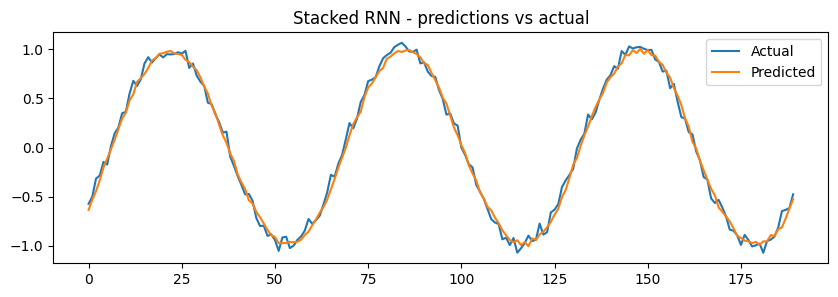

0.003615777529111252

In [11]:
stacked_rnn_model = Sequential([
    SimpleRNN(32, return_sequences=True, input_shape=(WINDOW_SIZE, 1)),
    SimpleRNN(32),
    Dense(1)
])
stacked_rnn_model.summary()
train_and_evaluate(stacked_rnn_model, "Stacked RNN")

### 8.2 Stacked LSTM

c:\Users\blk4524\AppData\Local\anaconda3\envs\nn\lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 50, 32)         │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 32)             │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,705 (49.63 KB)

 Trainable params: 12,705 (49.63 KB)

 Non-trainable params: 0 (0.00 B)

Stacked LSTM - Test MSE: 0.00278


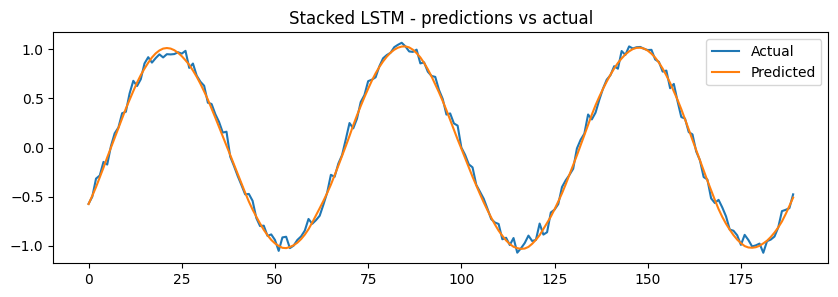

0.002775541251410435

In [12]:
stacked_lstm_model = Sequential([
    LSTM(32, return_sequences=True, input_shape=(WINDOW_SIZE, 1)),
    LSTM(32),
    Dense(1)
])
stacked_lstm_model.summary()
train_and_evaluate(stacked_lstm_model, "Stacked LSTM")

### 8.3 Stacked GRU

c:\Users\blk4524\AppData\Local\anaconda3\envs\nn\lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru_2 (GRU)                     │ (None, 50, 32)         │         3,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_3 (GRU)                     │ (None, 32)             │         6,336 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,729 (38.00 KB)

 Trainable params: 9,729 (38.00 KB)

 Non-trainable params: 0 (0.00 B)

Stacked GRU - Test MSE: 0.00327


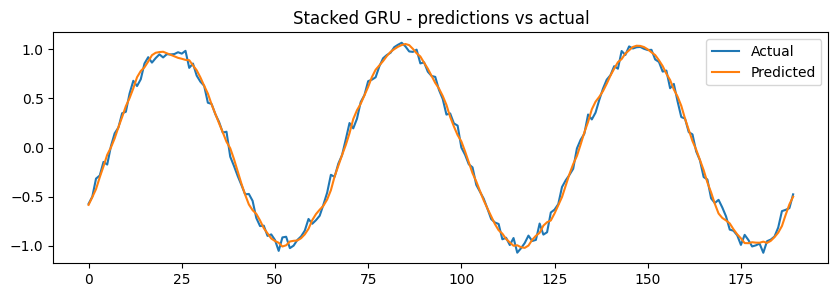

0.0032733335455578643

In [13]:
stacked_gru_model = Sequential([
    GRU(32, return_sequences=True, input_shape=(WINDOW_SIZE, 1)),
    GRU(32),
    Dense(1)
])
stacked_gru_model.summary()
train_and_evaluate(stacked_gru_model, "Stacked GRU")

## 9. Comparing all models

Finally, we line up the test MSE across all nine architectures, sorted from best to worst, to see which structure handled this sine wave prediction task most accurately.

In [14]:
results_df = pd.DataFrame(list(results.items()), columns=['Model', 'Test MSE'])
results_df = results_df.sort_values('Test MSE').reset_index(drop=True)
results_df

,Model,Test MSE
0,Bidirectional LSTM,0.002620
1,Simple RNN,0.002734
2,Stacked LSTM,0.002776
3,LSTM,0.002800
4,Bidirectional GRU,0.002934
5,Stacked GRU,0.003273
6,GRU,0.003315
7,Stacked RNN,0.003616
8,Bidirectional RNN,0.004622


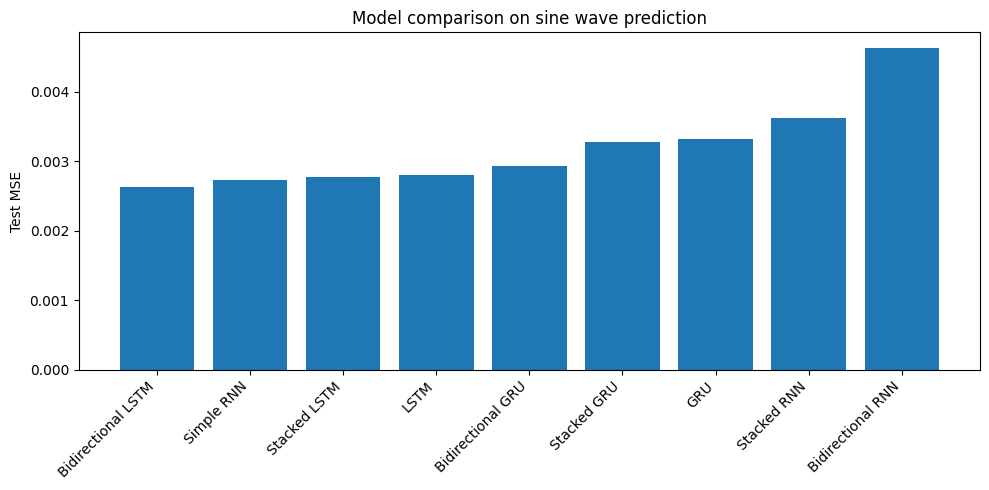

In [15]:
plt.figure(figsize=(10, 5))
plt.bar(results_df['Model'], results_df['Test MSE'])
plt.xticks(rotation=45, ha='right')
plt.ylabel('Test MSE')
plt.title('Model comparison on sine wave prediction')
plt.tight_layout()
plt.show()